In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path(".")

print("Current folder:", DATA_DIR.resolve())
print("\nCSV files found:")

for file in DATA_DIR.glob("*.csv"):
    print(file.name)

Current folder: /media/ashok/E-Drive/5th Semester/datascience/FreshCart_Project/FreshCart_Assessment_Dataset (3)

CSV files found:
products.csv
sales.csv
calendar.csv
stores.csv
promotions.csv


In [2]:
sales = pd.read_csv("sales.csv")
products = pd.read_csv("products.csv")
stores = pd.read_csv("stores.csv")
promotions = pd.read_csv("promotions.csv")
calendar = pd.read_csv("calendar.csv")

print("Sales:", sales.shape)
print("Products:", products.shape)
print("Stores:", stores.shape)
print("Promotions:", promotions.shape)
print("Calendar:", calendar.shape)


Sales: (36432, 6)
Products: (120, 5)
Stores: (20, 4)
Promotions: (9, 6)
Calendar: (731, 6)


In [3]:

# ==========================================
# STEP 1: DATA QUALITY ASSESSMENT
# ==========================================

datasets = {
    "Sales": sales,
    "Products": products,
    "Stores": stores,
    "Promotions": promotions,
    "Calendar": calendar
}

for name, df in datasets.items():
    print("\n" + "=" * 60)
    print(f"DATASET: {name.upper()}")
    print("=" * 60)

    print("\nShape:", df.shape)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nExact Duplicate Rows:", df.duplicated().sum())

    print("\nFirst 5 Records:")
    display(df.head())



DATASET: SALES

Shape: (36432, 6)

Column Names:
['date', 'store_id', 'product_id', 'units', 'revenue', 'promotion_code']

Data Types:
date               object
store_id           object
product_id         object
units               int64
revenue           float64
promotion_code     object
dtype: object

Missing Values:
date                  0
store_id              0
product_id            0
units                 0
revenue               0
promotion_code    30052
dtype: int64

Exact Duplicate Rows: 461

First 5 Records:


,date,store_id,product_id,units,revenue,promotion_code
0,2024-02-28,S03,P120,3,207.51,NaN
1,2024-02-13,S04,P060,1,100.21,PROMO001
2,2024-08-20,S06,P014,11,2365.33,NaN
3,2024-06-27,S19,P007,2,535.66,NaN
4,2025-10-03,S14,P063,12,310.18,PROMO008



DATASET: PRODUCTS

Shape: (120, 5)

Column Names:
['product_id', 'category', 'brand', 'price_band', 'unit_price']

Data Types:
product_id     object
category       object
brand          object
price_band     object
unit_price    float64
dtype: object

Missing Values:
product_id    0
category      0
brand         0
price_band    0
unit_price    0
dtype: int64

Exact Duplicate Rows: 0

First 5 Records:


,product_id,category,brand,price_band,unit_price
0,P001,Household,NorthStar,Premium,451.70
1,P002,Beverages,FreshCart Select,Budget,36.04
2,P003,Household,GoldenField,Mid-range,256.81
3,P004,Snacks,GoldenField,Mid-range,296.88
4,P005,Beverages,UrbanHarvest,Mid-range,220.62



DATASET: STORES

Shape: (20, 4)

Column Names:
['store_id', 'city', 'format', 'floor_area_sqft']

Data Types:
store_id           object
city               object
format             object
floor_area_sqft     int64
dtype: object

Missing Values:
store_id           0
city               0
format             0
floor_area_sqft    0
dtype: int64

Exact Duplicate Rows: 0

First 5 Records:


,store_id,city,format,floor_area_sqft
0,S01,Mysuru,Neighborhood,2645
1,S02,Chennai,Supermarket,4529
2,S03,Mysuru,Neighborhood,1842
3,S04,Mysuru,Neighborhood,1979
4,S05,Chennai,Hypermarket,13711



DATASET: PROMOTIONS

Shape: (9, 6)

Column Names:
['promotion_code', 'campaign', 'discount_pct', 'start_date', 'end_date', 'duration_days']

Data Types:
promotion_code    object
campaign          object
discount_pct       int64
start_date        object
end_date          object
duration_days      int64
dtype: object

Missing Values:
promotion_code    0
campaign          0
discount_pct      0
start_date        0
end_date          0
duration_days     0
dtype: int64

Exact Duplicate Rows: 0

First 5 Records:


,promotion_code,campaign,discount_pct,start_date,end_date,duration_days
0,PROMO001,Weekend Saver,10,2024-02-01,2024-02-18,18
1,PROMO002,Summer Refresh,15,2024-04-01,2024-04-21,21
2,PROMO003,Festival Specials,20,2024-10-01,2024-10-20,20
3,PROMO004,Year-End Deals,12,2024-12-10,2024-12-31,22
4,PROMO005,New Year Offers,10,2025-01-01,2025-01-14,14



DATASET: CALENDAR

Shape: (731, 6)

Column Names:
['date', 'weekday', 'holiday', 'festival', 'season', 'festival_flag']

Data Types:
date              object
weekday           object
holiday          float64
festival          object
season            object
festival_flag    float64
dtype: object

Missing Values:
date               0
weekday            0
holiday           18
festival         719
season             8
festival_flag     12
dtype: int64

Exact Duplicate Rows: 0

First 5 Records:


,date,weekday,holiday,festival,season,festival_flag
0,2024-01-01,Monday,0.0,NaN,Winter,0.0
1,2024-01-02,Tuesday,0.0,NaN,Winter,0.0
2,2024-01-03,Wednesday,0.0,NaN,Winter,0.0
3,2024-01-04,Thursday,0.0,NaN,Winter,0.0
4,2024-01-05,Friday,0.0,NaN,Winter,0.0


In [4]:

# ==========================================
# STEP 2: CHECK UNUSUAL SALES VALUES
# ==========================================

print("Units Summary:")
display(sales["units"].describe())

print("\nRecords with Zero Units:",
      (sales["units"] == 0).sum())

print("\nRecords with Negative Units:",
      (sales["units"] < 0).sum())

print("\nRecords with Zero Revenue:",
      (sales["revenue"] == 0).sum())

print("\nRecords with Negative Revenue:",
      (sales["revenue"] < 0).sum())

print("\nMissing Promotion Codes:",
      sales["promotion_code"].isnull().sum())

print("\nSample Invalid Records:")
display(
    sales[
        (sales["units"] <= 0) |
        (sales["revenue"] < 0)
    ].head(10)
)


Units Summary:


count    36432.000000
mean         6.278766
std          3.569659
min         -3.000000
25%          4.000000
50%          6.000000
75%          8.000000
max         36.000000
Name: units, dtype: float64


Records with Zero Units: 110

Records with Negative Units: 109

Records with Zero Revenue: 110

Records with Negative Revenue: 109

Missing Promotion Codes: 30052

Sample Invalid Records:


,date,store_id,product_id,units,revenue,promotion_code
75,2024-06-28,S16,P104,-3,-281.94,NaN
289,2024-05-23,S08,P018,0,0.00,NaN
750,2025-09-01,S07,P015,-2,-228.29,NaN
902,2024-01-27,S12,P078,-2,-373.28,NaN
1010,2024-07-26,S14,P037,-1,-210.45,NaN
1094,2025-08-13,S10,P109,-3,-231.52,NaN
1328,2024-04-05,S16,P063,0,0.00,PROMO002
1491,2024-02-16,S20,P017,-2,-413.76,PROMO001
2094,2025-12-04,S09,P021,-3,-403.21,NaN
2221,2024-06-02,S15,P076,0,0.00,NaN


In [5]:

# ==========================================
# STEP 3: CHECK CATEGORY CONSISTENCY
# ==========================================

print("Category Values:")
display(products["category"].value_counts(dropna=False))

print("\nUnique Category Count:",
      products["category"].nunique())

print("\nCalendar Missing Values:")
display(calendar.isnull().sum())


Category Values:


category
Personal Care     23
Fresh Produce     21
Dairy             19
Snacks            18
Beverages         16
Household         15
Beverage           2
Personal care      1
Snack              1
BEVERAGES          1
snacks             1
HOUSEHOLD          1
Dairy              1
Name: count, dtype: int64


Unique Category Count: 13

Calendar Missing Values:


date               0
weekday            0
holiday           18
festival         719
season             8
festival_flag     12
dtype: int64

In [6]:

# ==========================================
# STEP 4: DATA CLEANING AND PREPROCESSING
# ==========================================

# Preserve the original data
sales_raw = sales.copy()
products_raw = products.copy()
stores_raw = stores.copy()
promotions_raw = promotions.copy()
calendar_raw = calendar.copy()

# Create working copies
sales_clean = sales.copy()
products_clean = products.copy()
stores_clean = stores.copy()
promotions_clean = promotions.copy()
calendar_clean = calendar.copy()

# 1. Convert date columns to datetime
sales_clean["date"] = pd.to_datetime(
    sales_clean["date"], errors="coerce"
)

calendar_clean["date"] = pd.to_datetime(
    calendar_clean["date"], errors="coerce"
)

promotions_clean["start_date"] = pd.to_datetime(
    promotions_clean["start_date"], errors="coerce"
)

promotions_clean["end_date"] = pd.to_datetime(
    promotions_clean["end_date"], errors="coerce"
)

# 2. Standardize category names
category_mapping = {
    "dairy": "Dairy",
    "beverage": "Beverages",
    "beverages": "Beverages",
    "snack": "Snacks",
    "snacks": "Snacks",
    "fresh produce": "Fresh Produce",
    "household": "Household",
    "home care": "Household",
    "personal care": "Personal Care"
}

products_clean["category"] = (
    products_clean["category"]
    .str.strip()
    .str.lower()
    .map(category_mapping)
)

# 3. Remove exact duplicate sales rows
rows_before = len(sales_clean)
sales_clean = sales_clean.drop_duplicates().copy()
duplicates_removed = rows_before - len(sales_clean)

# 4. Exclude invalid sales from the primary analysis
invalid_mask = (
    (sales_clean["units"] <= 0) |
    (sales_clean["revenue"] < 0)
)

invalid_rows = int(invalid_mask.sum())

sales_clean = sales_clean.loc[~invalid_mask].copy()

# 5. Standardize missing promotion codes
# Keep a separate label: missing does not prove no promotion.
sales_clean["promotion_code"] = (
    sales_clean["promotion_code"]
    .fillna("NO_CODE_RECORDED")
    .str.strip()
)

# 6. Repair calendar fields
# In this synthetic dataset, holiday was generated as a
# weekend indicator. Therefore, infer missing flags from weekday.
calendar_clean["holiday"] = calendar_clean["holiday"].fillna(
    calendar_clean["date"].dt.dayofweek.ge(5).astype(int)
).astype(int)

# Empty festival names represent dates without a recorded festival.
calendar_clean["festival"] = calendar_clean["festival"].fillna("")

# Derive festival_flag from the festival name for consistency.
calendar_clean["festival_flag"] = (
    calendar_clean["festival"].str.strip().ne("")
).astype(int)

# Derive missing seasons from the documented month-based rule.
month = calendar_clean["date"].dt.month

season_mapping = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Summer", 4: "Summer", 5: "Summer",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon",
    9: "Festive", 10: "Festive", 11: "Festive"
}

calendar_clean["season"] = calendar_clean["season"].fillna(
    month.map(season_mapping)
)

# 7. Report cleaning results
print("CLEANING SUMMARY")
print("-" * 40)
print("Sales rows before cleaning:", len(sales_raw))
print("Exact duplicates removed:", duplicates_removed)
print("Invalid sales rows excluded:", invalid_rows)
print("Sales rows after cleaning:", len(sales_clean))
print("Products with missing categories:",
      products_clean["category"].isna().sum())

print("\nRemaining missing values in cleaned sales:")
display(sales_clean.isnull().sum())

print("\nRemaining missing values in cleaned calendar:")
display(calendar_clean.isnull().sum())

print("\nStandardized categories:")
display(products_clean["category"].value_counts())


CLEANING SUMMARY
----------------------------------------
Sales rows before cleaning: 36432
Exact duplicates removed: 461
Invalid sales rows excluded: 219
Sales rows after cleaning: 35752
Products with missing categories: 0

Remaining missing values in cleaned sales:


date              0
store_id          0
product_id        0
units             0
revenue           0
promotion_code    0
dtype: int64


Remaining missing values in cleaned calendar:


date             0
weekday          0
holiday          0
festival         0
season           0
festival_flag    0
dtype: int64


Standardized categories:


category
Personal Care    24
Fresh Produce    21
Dairy            20
Snacks           20
Beverages        19
Household        16
Name: count, dtype: int64

In [7]:

# ==========================================
# STEP 5A: VALIDATE JOIN KEYS
# ==========================================

print("PRODUCT ID duplicates:",
      products_clean["product_id"].duplicated().sum())

print("STORE ID duplicates:",
      stores_clean["store_id"].duplicated().sum())

print("PROMOTION CODE duplicates:",
      promotions_clean["promotion_code"].duplicated().sum())

print("CALENDAR DATE duplicates:",
      calendar_clean["date"].duplicated().sum())

print("\nSales rows before merging:", len(sales_clean))


PRODUCT ID duplicates: 0
STORE ID duplicates: 0
PROMOTION CODE duplicates: 0
CALENDAR DATE duplicates: 0

Sales rows before merging: 35752


In [8]:

# ==========================================
# STEP 5B: MERGE ALL FIVE DATASETS
# ==========================================

# Merge product information
df = sales_clean.merge(
    products_clean,
    on="product_id",
    how="left",
    validate="many_to_one",
    indicator="_product_merge"
)

# Merge store information
df = df.merge(
    stores_clean,
    on="store_id",
    how="left",
    validate="many_to_one",
    indicator="_store_merge"
)

# Merge promotion information
df = df.merge(
    promotions_clean,
    on="promotion_code",
    how="left",
    validate="many_to_one",
    indicator="_promotion_merge"
)

# Merge calendar information
df = df.merge(
    calendar_clean,
    on="date",
    how="left",
    validate="many_to_one",
    indicator="_calendar_merge"
)

# Check whether each sales record found a matching lookup record
print("PRODUCT MATCHES")
display(df["_product_merge"].value_counts())

print("\nSTORE MATCHES")
display(df["_store_merge"].value_counts())

print("\nPROMOTION MATCHES")
display(df["_promotion_merge"].value_counts())

print("\nCALENDAR MATCHES")
display(df["_calendar_merge"].value_counts())

# Remove temporary merge indicators after inspecting them
df = df.drop(columns=[
    "_product_merge",
    "_store_merge",
    "_promotion_merge",
    "_calendar_merge"
])

print("\nMerged dataset shape:", df.shape)
print("Clean sales rows:", len(sales_clean))
print("Merged sales rows:", len(df))

display(df.head())


PRODUCT MATCHES


_product_merge
both          35752
left_only         0
right_only        0
Name: count, dtype: int64


STORE MATCHES


_store_merge
both          35752
left_only         0
right_only        0
Name: count, dtype: int64


PROMOTION MATCHES


_promotion_merge
left_only     29492
both           6260
right_only        0
Name: count, dtype: int64


CALENDAR MATCHES


_calendar_merge
both          35752
left_only         0
right_only        0
Name: count, dtype: int64


Merged dataset shape: (35752, 23)
Clean sales rows: 35752
Merged sales rows: 35752


,date,store_id,product_id,units,revenue,promotion_code,category,brand,price_band,unit_price,...,campaign,discount_pct,start_date,end_date,duration_days,weekday,holiday,festival,season,festival_flag
0,2024-02-28,S03,P120,3,207.51,NO_CODE_RECORDED,Dairy,UrbanHarvest,Budget,69.17,...,NaN,NaN,NaT,NaT,NaN,Wednesday,0,,Winter,0
1,2024-02-13,S04,P060,1,100.21,PROMO001,Snacks,SunVale,Mid-range,111.34,...,Weekend Saver,10.0,2024-02-01,2024-02-18,18.0,Tuesday,0,,Winter,0
2,2024-08-20,S06,P014,11,2365.33,NO_CODE_RECORDED,Fresh Produce,GoldenField,Mid-range,215.03,...,NaN,NaN,NaT,NaT,NaN,Tuesday,0,,Monsoon,0
3,2024-06-27,S19,P007,2,535.66,NO_CODE_RECORDED,Household,DailyFarm,Mid-range,267.83,...,NaN,NaN,NaT,NaT,NaN,Thursday,0,,Monsoon,0
4,2025-10-03,S14,P063,12,310.18,PROMO008,Beverages,UrbanHarvest,Budget,32.31,...,Festival Specials,20.0,2025-10-01,2025-10-20,20.0,Friday,0,,Festive,0


In [9]:

# ==========================================
# STEP 5C: INTEGRATION QUALITY CHECK
# ==========================================

print("Final dataset shape:", df.shape)

print("\nMissing values after merging:")
display(df.isnull().sum())

print("\nUnique products:", df["product_id"].nunique())
print("Unique stores:", df["store_id"].nunique())
print("Unique categories:", df["category"].nunique())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nTotal units sold:", df["units"].sum())
print("Total revenue:", round(df["revenue"].sum(), 2))

# Save the integrated dataset
df.to_csv("freshcart_cleaned_merged.csv", index=False)

print("\nSaved: freshcart_cleaned_merged.csv")


Final dataset shape: (35752, 23)

Missing values after merging:


date                   0
store_id               0
product_id             0
units                  0
revenue                0
promotion_code         0
category               0
brand                  0
price_band             0
unit_price             0
city                   0
format                 0
floor_area_sqft        0
campaign           29492
discount_pct       29492
start_date         29492
end_date           29492
duration_days      29492
weekday                0
holiday                0
festival               0
season                 0
festival_flag          0
dtype: int64


Unique products: 120
Unique stores: 20
Unique categories: 6

Date range:
2024-01-01 00:00:00 to 2025-12-31 00:00:00

Total units sold: 226118
Total revenue: 40683811.08

Saved: freshcart_cleaned_merged.csv


CATEGORY PERFORMANCE SUMMARY


,category,Total_Revenue,Total_Units,Sales_Records,Unique_Products,Revenue_Share_Percent
0,Fresh Produce,9685609.26,43610,6300,21,23.81
1,Snacks,9425968.93,44849,5997,20,23.17
2,Beverages,6569092.10,44490,5765,19,16.15
3,Dairy,6500264.84,36313,5815,20,15.98
4,Personal Care,4755569.43,33117,7087,24,11.69
5,Household,3747306.52,23739,4788,16,9.21


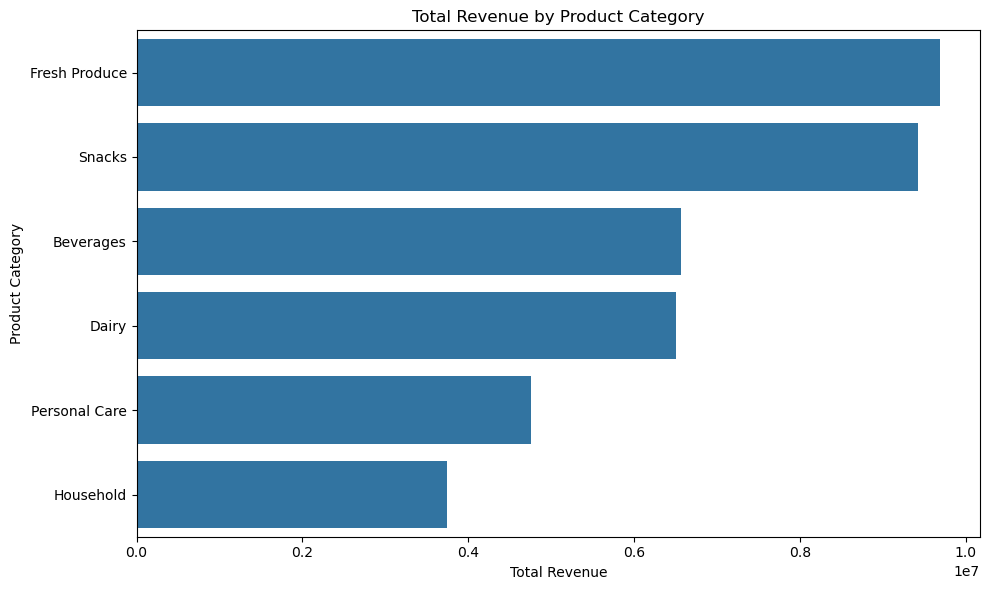

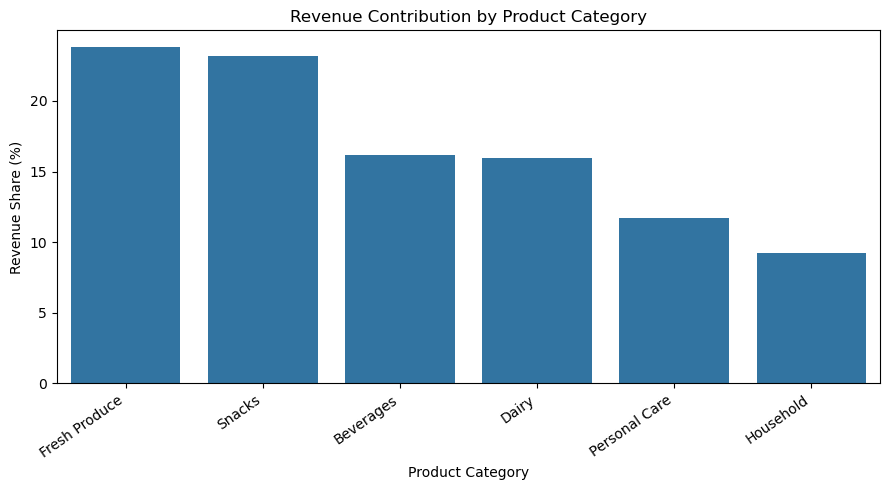

In [10]:

# ==========================================
# EDA 1: CATEGORY REVENUE ANALYSIS
# ==========================================

# Summarize sales by product category
category_analysis = (
    df.groupby("category", as_index=False)
    .agg(
        Total_Revenue=("revenue", "sum"),
        Total_Units=("units", "sum"),
        Sales_Records=("product_id", "count"),
        Unique_Products=("product_id", "nunique")
    )
)

# Calculate each category's contribution to total revenue
total_revenue = category_analysis["Total_Revenue"].sum()

category_analysis["Revenue_Share_Percent"] = (
    category_analysis["Total_Revenue"] / total_revenue * 100
)

# Sort from highest to lowest revenue
category_analysis = category_analysis.sort_values(
    "Total_Revenue", ascending=False
).reset_index(drop=True)

print("CATEGORY PERFORMANCE SUMMARY")
display(category_analysis.round(2))

# Bar chart: total revenue by category
plt.figure(figsize=(10, 6))
sns.barplot(
    data=category_analysis,
    x="Total_Revenue",
    y="category"
)
plt.title("Total Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

# Bar chart: revenue share by category
plt.figure(figsize=(9, 5))
sns.barplot(
    data=category_analysis,
    x="category",
    y="Revenue_Share_Percent"
)
plt.title("Revenue Contribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue Share (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


STORE YEAR-OVER-YEAR PERFORMANCE


year,2024,2025,Revenue_Change,Growth_Percent
store_id,,,,
S15,858473.11,1058643.30,200170.19,23.32
S09,763837.47,875494.90,111657.43,14.62
S11,1259517.94,1434413.10,174895.16,13.89
S14,1315056.72,1471298.97,156242.25,11.88
S06,1263331.98,1409861.90,146529.92,11.60
S03,733044.81,808227.01,75182.20,10.26
S17,1233078.48,1350812.03,117733.55,9.55
S19,708909.48,771050.96,62141.48,8.77
S02,963015.43,1037471.96,74456.53,7.73


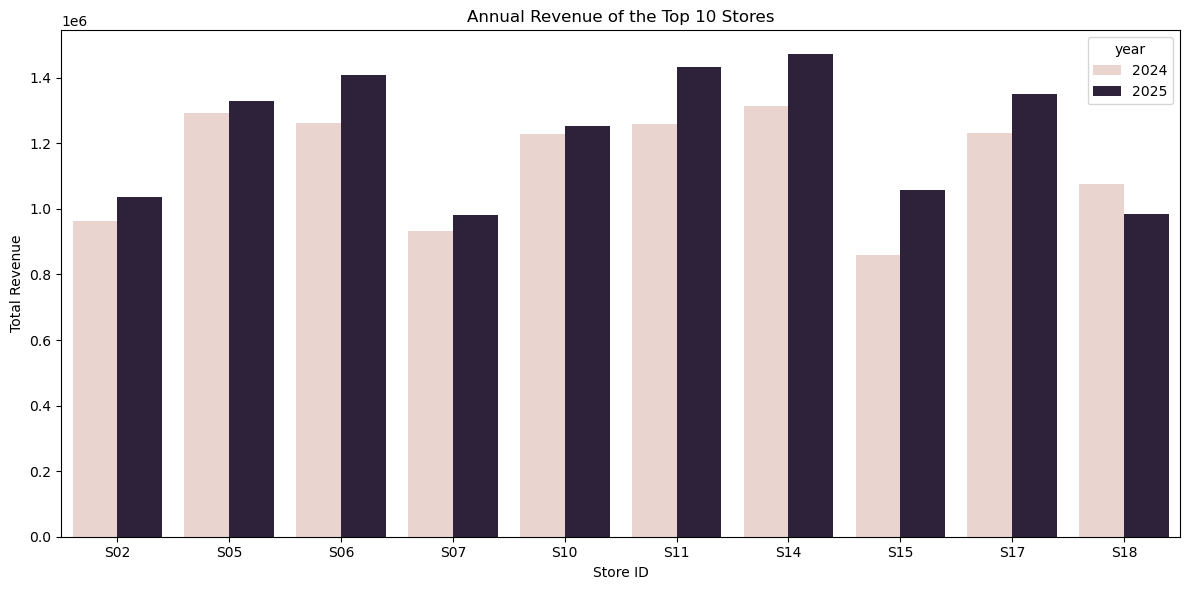

In [11]:

# ==========================================
# EDA 2: STORE PERFORMANCE AND GROWTH
# ==========================================

df["year"] = df["date"].dt.year

# Revenue by store and year
store_yearly = (
    df.groupby(["store_id", "year"])["revenue"]
    .sum()
    .unstack(fill_value=0)
)

# Ensure both years are available
for year in [2024, 2025]:
    if year not in store_yearly.columns:
        store_yearly[year] = 0

store_yearly = store_yearly[[2024, 2025]]

store_yearly["Revenue_Change"] = (
    store_yearly[2025] - store_yearly[2024]
)

store_yearly["Growth_Percent"] = np.where(
    store_yearly[2024] > 0,
    store_yearly["Revenue_Change"] / store_yearly[2024] * 100,
    np.nan
)

store_yearly = store_yearly.sort_values(
    "Growth_Percent", ascending=False
)

print("STORE YEAR-OVER-YEAR PERFORMANCE")
display(store_yearly.round(2))

# Visualize annual revenue for the top 10 stores by total revenue
top_stores = (
    df.groupby("store_id")["revenue"]
    .sum()
    .nlargest(10)
    .index
)

store_plot_data = (
    df[df["store_id"].isin(top_stores)]
    .groupby(["store_id", "year"], as_index=False)["revenue"]
    .sum()
)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=store_plot_data,
    x="store_id",
    y="revenue",
    hue="year"
)
plt.title("Annual Revenue of the Top 10 Stores")
plt.xlabel("Store ID")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()


In [12]:

# ==========================================
# EDA 2A: CHECK YEARLY DATA COVERAGE
# ==========================================

yearly_coverage = (
    df.groupby(["store_id", "year"])
    .agg(
        Sales_Records=("revenue", "size"),
        Recorded_Revenue=("revenue", "sum"),
        Recorded_Units=("units", "sum")
    )
    .reset_index()
)

print("YEARLY RECORD COVERAGE BY STORE")
display(
    yearly_coverage.sort_values(
        ["store_id", "year"]
    ).round(2)
)

# Compare the total number of records by year
print("\nTOTAL RECORDS BY YEAR")
display(
    df.groupby("year")
    .agg(
        Sales_Records=("revenue", "size"),
        Recorded_Revenue=("revenue", "sum"),
        Recorded_Units=("units", "sum")
    )
    .round(2)
)


YEARLY RECORD COVERAGE BY STORE


,store_id,year,Sales_Records,Recorded_Revenue,Recorded_Units
0,S01,2024,907,847610.50,4357
1,S01,2025,895,769971.79,4489
2,S02,2024,922,963015.43,5298
3,S02,2025,889,1037471.96,5516
4,S03,2024,869,733044.81,4359
5,S03,2025,897,808227.01,4535
6,S04,2024,897,747073.02,4297
7,S04,2025,870,800335.77,4341
8,S05,2024,862,1291649.58,7079
9,S05,2025,874,1329394.90,7212



TOTAL RECORDS BY YEAR


,Sales_Records,Recorded_Revenue,Recorded_Units
year,,,
2024,17743,19781173.70,110792
2025,18009,20902637.38,115326


PROMOTION VS NO RECORDED CODE


,is_promotion_recorded,Sales_Records,Total_Revenue,Total_Units,Average_Revenue_Per_Record,Average_Units_Per_Record,Record_Type
0,0,29492,32990469.80,177848,1118.62,6.03,No code recorded
1,1,6260,7693341.28,48270,1228.97,7.71,Recognized promotion



CAMPAIGN PERFORMANCE


,promotion_code,campaign,discount_pct,Sales_Records,Total_Revenue,Total_Units,Average_Revenue_Per_Record,Average_Units_Per_Record
3,PROMO004,Year-End Deals,12.0,756,984855.45,5533,1302.72,7.32
5,PROMO006,Summer Refresh,15.0,786,972706.70,6250,1237.54,7.95
8,PROMO009,Year-End Deals,12.0,777,959805.62,5811,1235.27,7.48
7,PROMO008,Festival Specials,20.0,687,916530.50,6038,1334.11,8.79
6,PROMO007,Mid-Year Mega Sale,18.0,715,886226.53,5632,1239.48,7.88
1,PROMO002,Summer Refresh,15.0,733,866134.31,5671,1181.63,7.74
2,PROMO003,Festival Specials,20.0,705,844923.36,5748,1198.47,8.15
0,PROMO001,Weekend Saver,10.0,631,668259.28,4209,1059.05,6.67
4,PROMO005,New Year Offers,10.0,470,593899.53,3378,1263.62,7.19


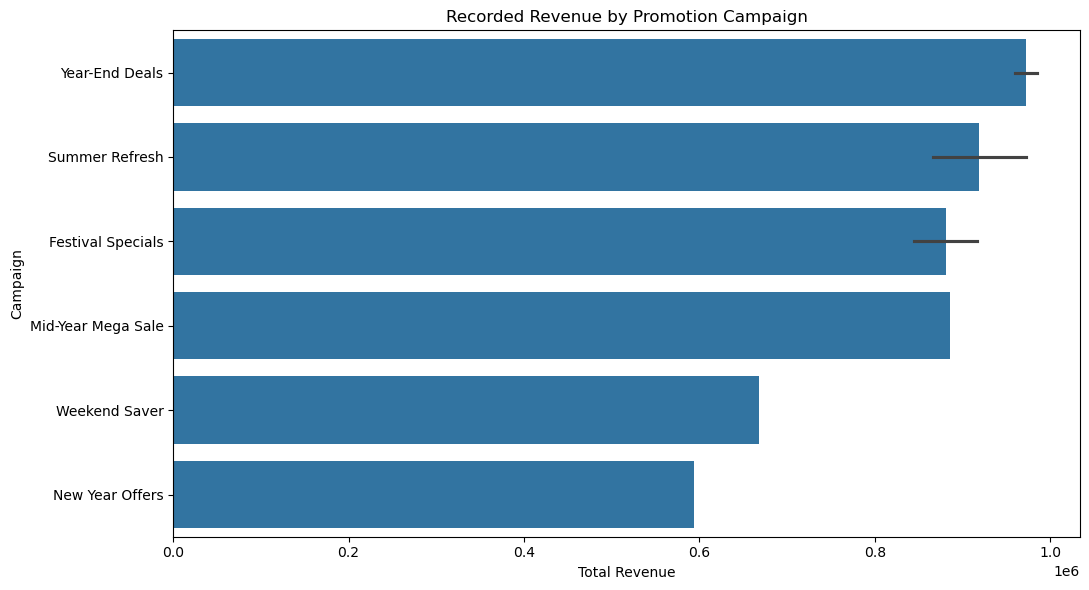

In [13]:

# ==========================================
# EDA 3: PROMOTION IMPACT ANALYSIS
# ==========================================

# Identify records with a recognized promotion code
df["is_promotion_recorded"] = (
    df["promotion_code"].ne("NO_CODE_RECORDED")
    & df["campaign"].notna()
).astype(int)

# Compare recorded sales performance
promotion_comparison = (
    df.groupby("is_promotion_recorded")
    .agg(
        Sales_Records=("revenue", "size"),
        Total_Revenue=("revenue", "sum"),
        Total_Units=("units", "sum"),
        Average_Revenue_Per_Record=("revenue", "mean"),
        Average_Units_Per_Record=("units", "mean")
    )
    .reset_index()
)

promotion_comparison["Record_Type"] = (
    promotion_comparison["is_promotion_recorded"]
    .map({
        1: "Recognized promotion",
        0: "No code recorded"
    })
)

print("PROMOTION VS NO RECORDED CODE")
display(promotion_comparison.round(2))

# Compare recognized campaigns
campaign_analysis = (
    df[df["campaign"].notna()]
    .groupby(["promotion_code", "campaign", "discount_pct"])
    .agg(
        Sales_Records=("revenue", "size"),
        Total_Revenue=("revenue", "sum"),
        Total_Units=("units", "sum"),
        Average_Revenue_Per_Record=("revenue", "mean"),
        Average_Units_Per_Record=("units", "mean")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

print("\nCAMPAIGN PERFORMANCE")
display(campaign_analysis.round(2))

# Visualize revenue by recognized campaign
plt.figure(figsize=(11, 6))
sns.barplot(
    data=campaign_analysis,
    x="Total_Revenue",
    y="campaign"
)
plt.title("Recorded Revenue by Promotion Campaign")
plt.xlabel("Total Revenue")
plt.ylabel("Campaign")
plt.tight_layout()
plt.show()


FESTIVAL COMPARISON


,festival_flag,Records,Revenue,Avg_Revenue_Per_Record,Units,Avg_Units_Per_Record,Period
0,0,35147,39673572.27,1128.79,220050,6.26,Non-festival
1,1,605,1010238.81,1669.82,6068,10.03,Festival


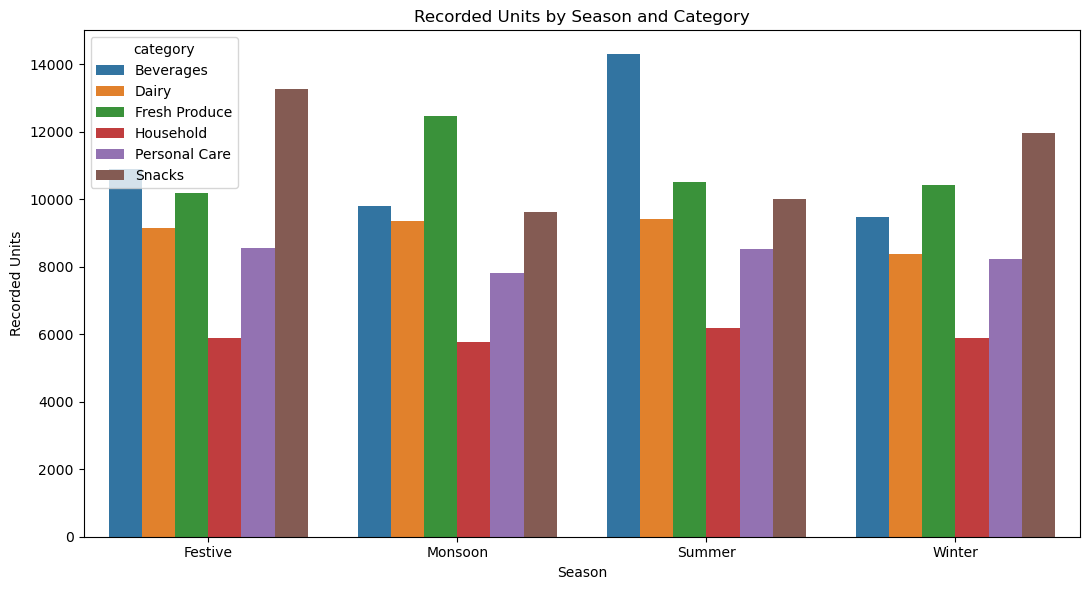

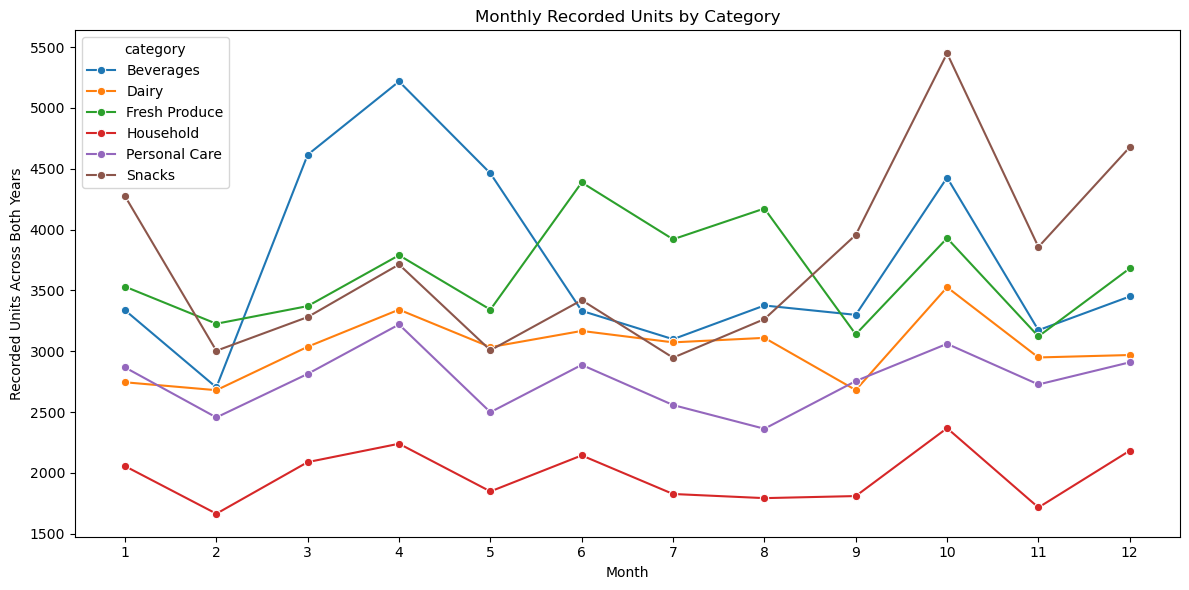

WEEKDAY PERFORMANCE


,weekday,Records,Revenue,Avg_Revenue_Per_Record,Units
0,Monday,5076,5503008.76,1084.12,30440
1,Tuesday,5224,5528276.19,1058.25,30745
2,Wednesday,5135,5563091.39,1083.37,30481
3,Thursday,5076,5409093.58,1065.62,30862
4,Friday,5101,5411369.99,1060.84,30273
5,Saturday,5091,6704967.20,1317.02,36697
6,Sunday,5049,6564003.97,1300.06,36620


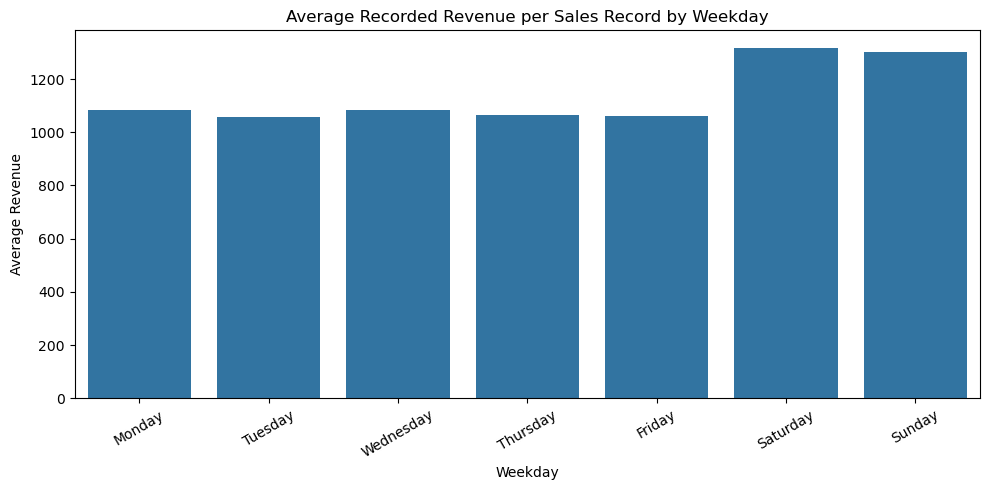


MONTHLY REVENUE RANKING


month
10    3803397.27
4     3557285.31
1     3526386.39
3     3518743.10
12    3507181.88
6     3441020.26
8     3361083.03
5     3332281.74
11    3271619.44
7     3257255.21
9     3256538.18
2     2851019.27
Name: revenue, dtype: float64

In [14]:

# ==========================================
# EDA 4: FESTIVAL, SEASONAL & PEAK PERIODS
# ==========================================

# 1. Festival vs non-festival demand
festival_analysis = (
    df.groupby("festival_flag")
    .agg(
        Records=("revenue", "size"),
        Revenue=("revenue", "sum"),
        Avg_Revenue_Per_Record=("revenue", "mean"),
        Units=("units", "sum"),
        Avg_Units_Per_Record=("units", "mean")
    )
    .reset_index()
)

festival_analysis["Period"] = festival_analysis["festival_flag"].map(
    {0: "Non-festival", 1: "Festival"}
)

print("FESTIVAL COMPARISON")
display(festival_analysis.round(2))

# 2. Seasonal category demand
seasonal_analysis = (
    df.groupby(["season", "category"])
    .agg(
        Revenue=("revenue", "sum"),
        Units=("units", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=seasonal_analysis,
    x="season",
    y="Units",
    hue="category",
    estimator="sum",
    errorbar=None
)
plt.title("Recorded Units by Season and Category")
plt.xlabel("Season")
plt.ylabel("Recorded Units")
plt.tight_layout()
plt.show()

# Monthly demand trends
df["month"] = df["date"].dt.month

monthly = (
    df.groupby(["month", "category"])["units"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=monthly,
    x="month",
    y="units",
    hue="category",
    marker="o"
)
plt.title("Monthly Recorded Units by Category")
plt.xlabel("Month")
plt.ylabel("Recorded Units Across Both Years")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# 3. Peak shopping periods: weekday
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_analysis = (
    df.groupby("weekday")
    .agg(
        Records=("revenue", "size"),
        Revenue=("revenue", "sum"),
        Avg_Revenue_Per_Record=("revenue", "mean"),
        Units=("units", "sum")
    )
    .reindex(weekday_order)
    .reset_index()
)

print("WEEKDAY PERFORMANCE")
display(weekday_analysis.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(
    data=weekday_analysis,
    x="weekday",
    y="Avg_Revenue_Per_Record"
)
plt.title("Average Recorded Revenue per Sales Record by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Peak months
monthly_revenue = (
    df.groupby("month")["revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("\nMONTHLY REVENUE RANKING")
display(monthly_revenue.round(2))


In [15]:

# ==========================================
# FEATURE ENGINEERING
# ==========================================

# 1. Date and time features
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek
df["quarter"] = df["date"].dt.quarter
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

# 2. Promotion indicator
df["is_promotion_recorded"] = (
    df["promotion_code"].ne("NO_CODE_RECORDED")
    & df["campaign"].notna()
).astype(int)

# 3. Revenue per unit
df["revenue_per_unit"] = df["revenue"] / df["units"]

# 4. Store revenue per square foot
# This is a store-level metric, not a transaction-level productivity measure.
store_revenue = df.groupby("store_id")["revenue"].sum()
store_area = stores_clean.set_index("store_id")["floor_area_sqft"]

store_productivity = (
    store_revenue / store_area
).rename("total_revenue_per_sqft")

df = df.merge(
    store_productivity,
    on="store_id",
    how="left",
    validate="many_to_one"
)

# 5. Create a monthly analysis key
df["month_year"] = df["date"].dt.to_period("M").astype(str)

print("Feature engineering completed.")
print("\nNew and important features:")
display(df[[
    "date", "year", "month", "day_of_week", "is_weekend",
    "is_promotion_recorded", "revenue_per_unit",
    "total_revenue_per_sqft", "month_year"
]].head())

print("\nFinal dataset shape:", df.shape)


Feature engineering completed.

New and important features:


,date,year,month,day_of_week,is_weekend,is_promotion_recorded,revenue_per_unit,total_revenue_per_sqft,month_year
0,2024-02-28,2024,2,2,0,0,69.170000,836.738230,2024-02
1,2024-02-13,2024,2,1,0,1,100.210000,781.914497,2024-02
2,2024-08-20,2024,8,1,0,0,215.030000,179.252590,2024-08
3,2024-06-27,2024,6,3,0,0,267.830000,338.663716,2024-06
4,2025-10-03,2025,10,4,0,1,25.848333,163.537721,2025-10



Final dataset shape: (35752, 33)


In [16]:

print("Final dataset shape:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values by column:")
missing_summary = df.isnull().sum()
display(missing_summary[missing_summary > 0])

print("\nNumeric correlation with revenue:")
display(
    df.select_dtypes(include="number")
      .corr()["revenue"]
      .sort_values(ascending=False)
)


Final dataset shape: (35752, 33)

Duplicate rows: 0

Missing values by column:


campaign         29492
discount_pct     29492
start_date       29492
end_date         29492
duration_days    29492
dtype: int64


Numeric correlation with revenue:


revenue                   1.000000
unit_price                0.798083
revenue_per_unit          0.791521
units                     0.450198
floor_area_sqft           0.154810
is_weekend                0.075367
holiday                   0.075367
day_of_week               0.057198
festival_flag             0.048985
is_promotion_recorded     0.029438
year                      0.016077
discount_pct              0.015485
duration_days             0.010611
quarter                   0.009183
month                     0.007811
day                       0.000027
total_revenue_per_sqft   -0.122972
Name: revenue, dtype: float64

In [17]:
df.to_csv("freshcart_final_eda_dataset.csv", index=False)
print("Final dataset exported successfully.")

Final dataset exported successfully.


In [18]:

# Final validation for Round 2

from pathlib import Path

output_file = Path("freshcart_final_eda_dataset.csv")

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())
print("Export file exists:", output_file.exists())

if output_file.exists():
    print("Export file size (KB):",
          round(output_file.stat().st_size / 1024, 2))

print("\nRemaining missing values by column:")
display(df.isnull().sum()[df.isnull().sum() > 0])


Dataset shape: (35752, 33)
Duplicate rows: 0
Total missing values: 147460
Export file exists: True
Export file size (KB): 6764.07

Remaining missing values by column:


campaign         29492
discount_pct     29492
start_date       29492
end_date         29492
duration_days    29492
dtype: int64